Upload the zip file to colab

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving archive.zip to archive.zip


Extract the dataset

In [ ]:
import zipfile

with zipfile.ZipFile("archive.zip", "r") as zip_ref:
    zip_ref.extractall("/Data_set")

In [ ]:
import os
print(os.listdir("/content"))

['.config', 'archive.zip', 'sample_data']


In [ ]:
import zipfile
import os

# Location of your ZIP file
zip_path = "/content/archive.zip"

# Folder where we want to extract the dataset
extract_path = "/content/Data_set"

# Extract the ZIP file
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_path)

# Check what was extracted
print(os.listdir(extract_path))

['Testing', 'Training']


Check that everything is there

In [ ]:
import os

dataset_path = "/content/Data_set"

print("Dataset folders:")
print(os.listdir(dataset_path))

print("\nTraining folders:")
print(os.listdir(dataset_path + "/Training"))

print("\nTesting folders:")
print(os.listdir(dataset_path + "/Testing"))

Dataset folders:
['Testing', 'Training']

Training folders:
['glioma', 'meningioma', 'pituitary', 'notumor']

Testing folders:
['glioma', 'meningioma', 'pituitary', 'notumor']


In [ ]:
print(os.getcwd())
print(os.listdir("/content/Data_set/Testing"))

/content
['glioma', 'meningioma', 'pituitary', 'notumor']


In [ ]:
print(os.listdir("/content/Data_set/Training"))

['glioma', 'meningioma', 'pituitary', 'notumor']


**Data Preprocessing**

Step 1 — Check corrupted/unreadable images

In [ ]:
from PIL import Image


dataset_path = "/Data_set"

classes = ["glioma", "meningioma", "pituitary", "notumor"]

def check_images(split):
    bad_images = []

    for cls in classes:
        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):
            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:
                    img.verify()
            except Exception:
                bad_images.append(filepath)

    return bad_images


bad_training = check_images("Training")
bad_testing = check_images("Testing")

print("Bad training images:", len(bad_training))
print("Bad testing images:", len(bad_testing))

Bad training images: 0
Bad testing images: 0


Step 2 : Checking the class distribution

In [ ]:
classes = ["glioma", "meningioma", "pituitary", "notumor"]

for split in ["Training", "Testing"]:
    print(f"\n{split}")
    print("-" * 30)

    for cls in classes:
        folder = os.path.join(dataset_path, split, cls)
        count = len(os.listdir(folder))
        print(f"{cls}: {count}")


Training
------------------------------
glioma: 1400
meningioma: 1400
pituitary: 1400
notumor: 1400

Testing
------------------------------
glioma: 400
meningioma: 400
pituitary: 400
notumor: 400


# Before deciding on resizing, normalization, augmentation, or even the model input format, we should first characterize the raw images.

Image dimensions — e.g. 512×512, 300×400, etc.

Number of channels — RGB, grayscale, RGBA, etc.

Image formats — JPG, PNG, etc.

Pixel-value range

Aspect-ratio distribution

Class-wise image counts — already checked

Corrupted images — already checked

In [ ]:
from PIL import Image
import os
from collections import Counter

dataset_path = "/content/Data_set"

classes = ["glioma", "meningioma", "pituitary", "notumor"]

def analyze_images(split):

    sizes = Counter()
    modes = Counter()
    formats = Counter()

    total_images = 0

    for cls in classes:

        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):

            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:

                    total_images += 1

                    # Image dimensions
                    sizes[img.size] += 1

                    # RGB, L (grayscale), RGBA, etc.
                    modes[img.mode] += 1

                    # JPG, PNG, etc.
                    formats[img.format] += 1

            except Exception:
                pass

    return total_images, sizes, modes, formats


for split in ["Training", "Testing"]:

    total, sizes, modes, formats = analyze_images(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Total images:", total)

    print("\nImage modes:")
    for mode, count in modes.items():
        print(f"{mode}: {count}")

    print("\nImage formats:")
    for fmt, count in formats.items():
        print(f"{fmt}: {count}")

    print("\nNumber of unique image sizes:", len(sizes))

    print("\nMost common image sizes:")
    for size, count in sizes.most_common(10):
        print(f"{size}: {count}")


Training
Total images: 5600

Image modes:
L: 2358
RGB: 3238
RGBA: 3
P: 1

Image formats:
JPEG: 5596
PNG: 4

Number of unique image sizes: 381

Most common image sizes:
(512, 512): 4012
(225, 225): 253
(630, 630): 69
(201, 251): 40
(236, 236): 39
(442, 442): 38
(150, 198): 33
(228, 221): 32
(232, 217): 32
(428, 417): 31

Testing
Total images: 1600

Image modes:
RGB: 891
L: 709

Image formats:
JPEG: 1600

Number of unique image sizes: 203

Most common image sizes:
(512, 512): 1002
(225, 225): 85
(630, 630): 21
(228, 221): 19
(227, 222): 19
(232, 217): 18
(201, 251): 17
(200, 252): 14
(300, 168): 13
(256, 256): 11


Before resizing images in to the same dimensions we want to look in to the aspect ratio

In [ ]:
from PIL import Image
import os
import numpy as np

dataset_path = "/content/Data_set"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

def get_aspect_ratios(split):

    aspect_ratios = []

    for cls in classes:

        folder = os.path.join(dataset_path, split, cls)

        for filename in os.listdir(folder):

            filepath = os.path.join(folder, filename)

            try:
                with Image.open(filepath) as img:

                    width, height = img.size

                    aspect_ratio = width / height

                    aspect_ratios.append(aspect_ratio)

            except Exception:
                pass

    return aspect_ratios


for split in ["Training", "Testing"]:

    ratios = get_aspect_ratios(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Number of images:", len(ratios))
    print("Minimum:", min(ratios))
    print("Maximum:", max(ratios))
    print("Mean:", np.mean(ratios))
    print("Median:", np.median(ratios))
    print("Std:", np.std(ratios))


Training
Number of images: 5600
Minimum: 0.644808743169399
Maximum: 1.7857142857142858
Mean: 0.9884351556534875
Median: 1.0
Std: 0.07929330130401531

Testing
Number of images: 1600
Minimum: 0.7169811320754716
Maximum: 1.7857142857142858
Mean: 0.9941241920027886
Median: 1.0
Std: 0.1256382671439496


In the training dataset the mean is 0.9884 and the median is 1.0 and in the testing dataset the mean is 0.994 and the median is 1.0 so i think the existing aspect ratios are good

Croping the image dataset

In [ ]:
!pip install imutils

import cv2
import numpy as np
import imutils
from PIL import Image


def crop_img(img):
    """
    Remove unnecessary background/margins from a brain MRI.

    Based on the preprocessing method provided by the
    dataset author.
    """

    # OpenCV loads images as BGR
    gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    # Smooth the image
    gray = cv2.GaussianBlur(gray, (3, 3), 0)

    # Threshold
    thresh = cv2.threshold(
        gray,
        45,
        255,
        cv2.THRESH_BINARY
    )[1]

    # Remove small noise
    thresh = cv2.erode(
        thresh,
        None,
        iterations=2
    )

    thresh = cv2.dilate(
        thresh,
        None,
        iterations=2
    )

    # Find external contours
    cnts = cv2.findContours(
        thresh.copy(),
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cnts = imutils.grab_contours(cnts)

    # If no contour is found, return original image
    if len(cnts) == 0:
        return img.copy()

    # Largest contour
    c = max(cnts, key=cv2.contourArea)

    # Extreme points
    extLeft = tuple(c[c[:, :, 0].argmin()][0])
    extRight = tuple(c[c[:, :, 0].argmax()][0])
    extTop = tuple(c[c[:, :, 1].argmin()][0])
    extBot = tuple(c[c[:, :, 1].argmax()][0])

    # No additional pixels, same as author's ADD_PIXELS = 0
    ADD_PIXELS = 0

    # Image dimensions
    h, w = img.shape[:2]

    # Make sure crop coordinates stay inside image
    x1 = max(extLeft[0] - ADD_PIXELS, 0)
    x2 = min(extRight[0] + ADD_PIXELS, w)

    y1 = max(extTop[1] - ADD_PIXELS, 0)
    y2 = min(extBot[1] + ADD_PIXELS, h)

    # Crop
    new_img = img[y1:y2, x1:x2].copy()

    return new_img

Test croping

In [ ]:
import os

folder = "/content/Data_set/Training/glioma"

files = os.listdir(folder)

print(files[:10])

['Tr-gl_1028.jpg', 'Tr-gl_1249.jpg', 'Tr-gl_344.jpg', 'Tr-gl_862.jpg', 'Tr-gl_600.jpg', 'Tr-gl_1085.jpg', 'Tr-gl_674.jpg', 'Tr-gl_756.jpg', 'Tr-gl_283.jpg', 'Tr-gl_156.jpg']


In [ ]:
import os
import cv2
from tqdm import tqdm

# Original dataset
dataset_path = "/content/Data_set"

# New dataset for cropped images
cropped_path = "/content/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

splits = [
    "Training",
    "Testing"
]


for split in splits:

    for cls in classes:

        # Input folder
        input_folder = os.path.join(
            dataset_path,
            split,
            cls
        )

        # Output folder
        output_folder = os.path.join(
            cropped_path,
            split,
            cls
        )

        # Create output folder
        os.makedirs(
            output_folder,
            exist_ok=True
        )

        # Get all files
        files = os.listdir(input_folder)

        print(f"\nProcessing {split}/{cls}")
        print("Images:", len(files))

        # Process every image
        for filename in tqdm(files):

            input_path = os.path.join(
                input_folder,
                filename
            )

            output_path = os.path.join(
                output_folder,
                filename
            )

            # Read image
            image = cv2.imread(input_path)

            # Check if image was readable
            if image is None:
                print("Could not read:", input_path)
                continue

            # Crop margins
            cropped = crop_img(image)

            # Save cropped image
            cv2.imwrite(
                output_path,
                cropped
            )

print("\nCropping completed!")


Processing Training/glioma
Images: 1400


100%|██████████| 1400/1400 [00:09<00:00, 154.15it/s]



Processing Training/meningioma
Images: 1400


100%|██████████| 1400/1400 [00:04<00:00, 324.00it/s]



Processing Training/pituitary
Images: 1400


100%|██████████| 1400/1400 [00:06<00:00, 205.58it/s]


... (7 outputs left out)

100%|██████████| 400/400 [00:01<00:00, 282.19it/s]



Processing Testing/notumor
Images: 400


100%|██████████| 400/400 [00:00<00:00, 586.20it/s]


Cropping completed!


Display original vs cropped

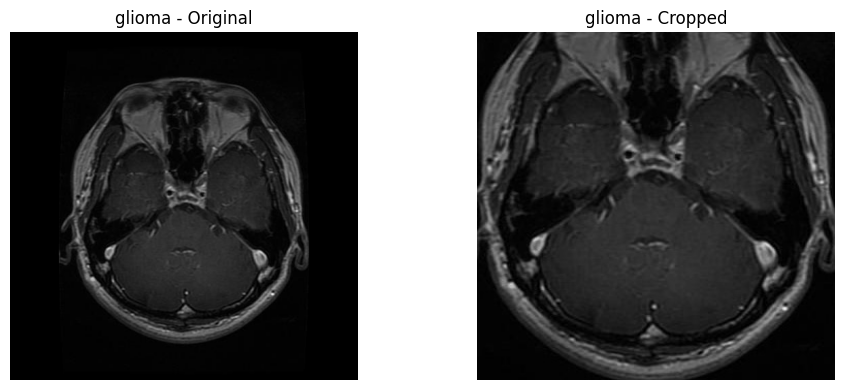

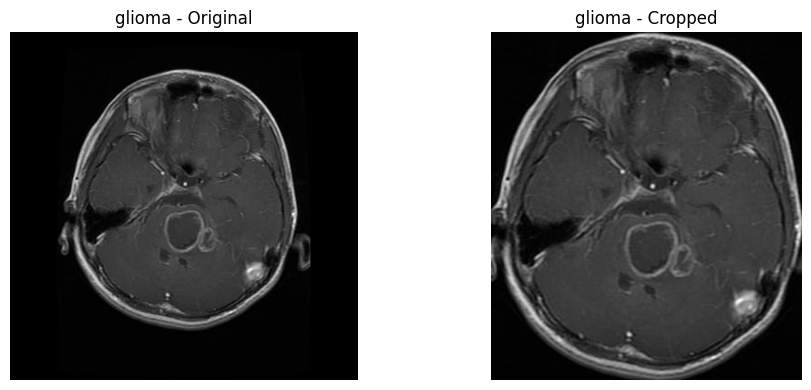

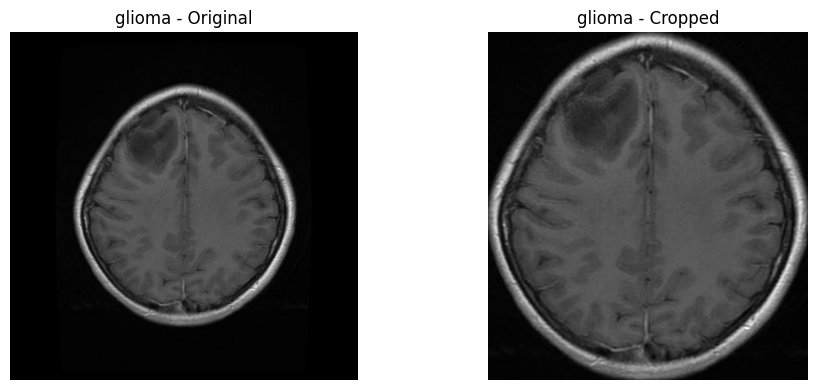

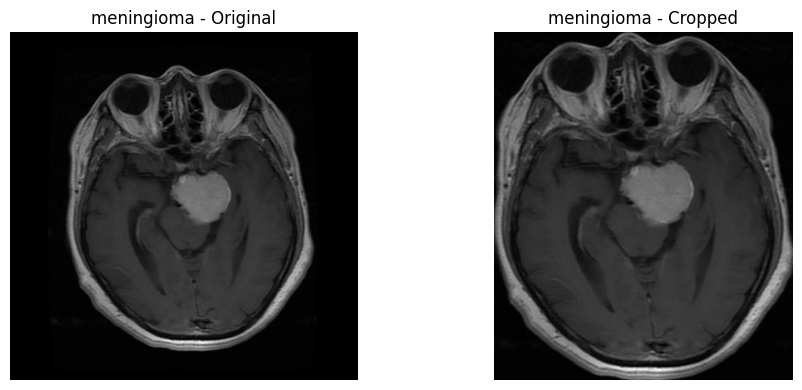

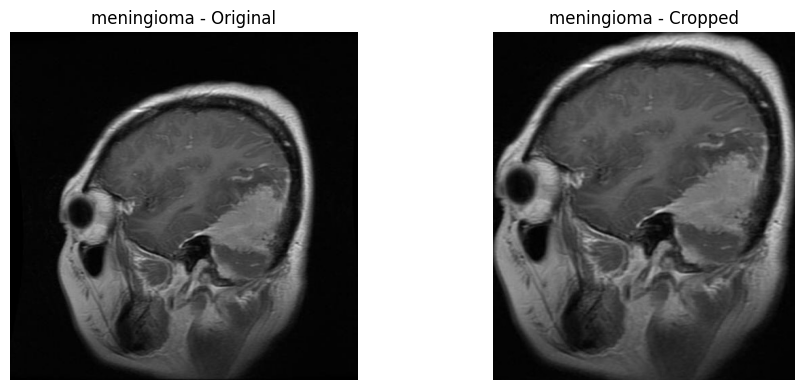

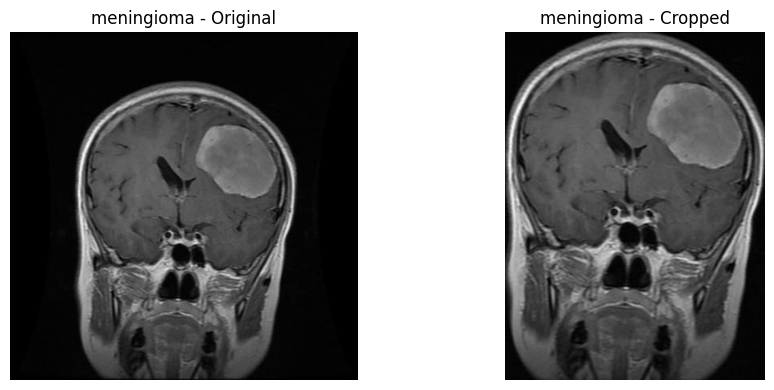

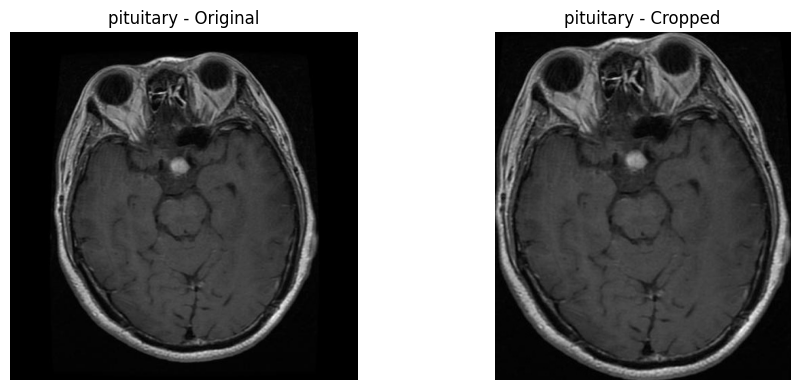

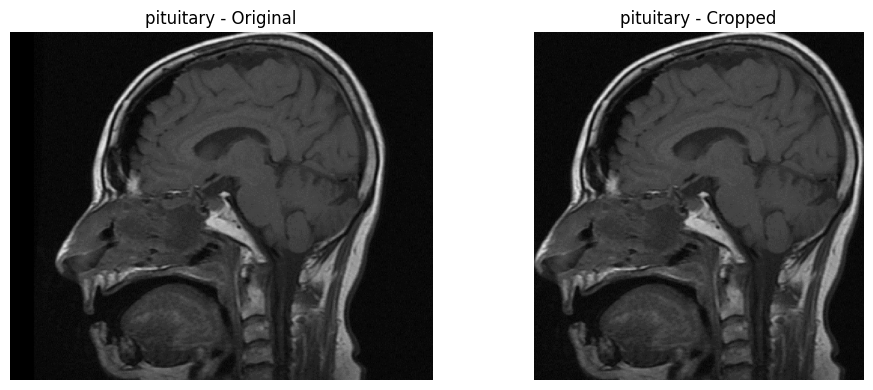

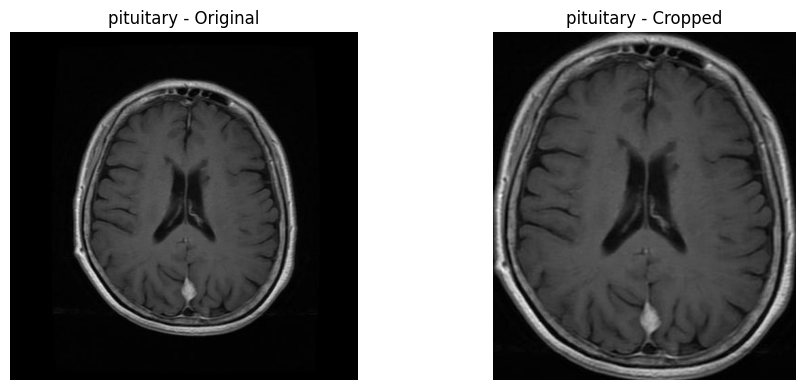

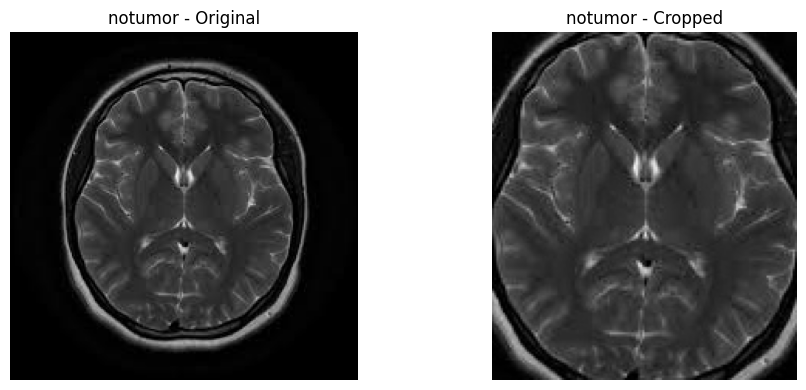

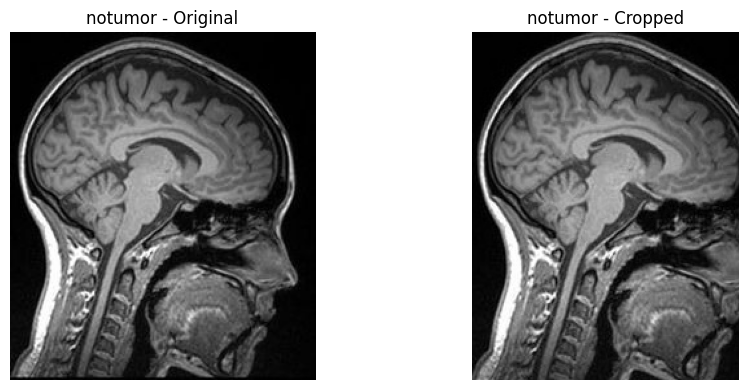

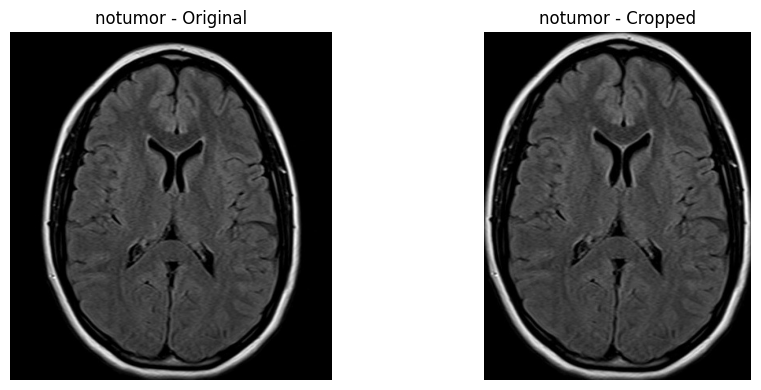

In [ ]:
import os
import cv2
import matplotlib.pyplot as plt
import random

original_path = "/content/Data_set"
cropped_path = "/content/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

split = "Training"

# Number of examples per class
num_examples = 3

for cls in classes:

    original_folder = os.path.join(
        original_path,
        split,
        cls
    )

    cropped_folder = os.path.join(
        cropped_path,
        split,
        cls
    )

    # Get original images
    files = [
        f for f in os.listdir(original_folder)
        if os.path.isfile(os.path.join(original_folder, f))
    ]

    # Randomly select images
    selected_files = random.sample(
        files,
        min(num_examples, len(files))
    )

    for filename in selected_files:

        original_file = os.path.join(
            original_folder,
            filename
        )

        cropped_file = os.path.join(
            cropped_folder,
            filename
        )

        # Read images
        original = cv2.imread(original_file)
        cropped = cv2.imread(cropped_file)

        # Convert BGR → RGB
        original = cv2.cvtColor(
            original,
            cv2.COLOR_BGR2RGB
        )

        cropped = cv2.cvtColor(
            cropped,
            cv2.COLOR_BGR2RGB
        )

        # Display
        plt.figure(figsize=(10, 4))

        plt.subplot(1, 2, 1)
        plt.imshow(original)
        plt.title(f"{cls} - Original")
        plt.axis("off")

        plt.subplot(1, 2, 2)
        plt.imshow(cropped)
        plt.title(f"{cls} - Cropped")
        plt.axis("off")

        plt.tight_layout()
        plt.show()

Analyze the cropped images

In [ ]:
from PIL import Image
import os
import numpy as np

cropped_path = "/content/Cropped"

classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]


def analyze_cropped_images(split):

    aspect_ratios = []
    widths = []
    heights = []

    for cls in classes:

        folder = os.path.join(
            cropped_path,
            split,
            cls
        )

        for filename in os.listdir(folder):

            filepath = os.path.join(
                folder,
                filename
            )

            try:
                with Image.open(filepath) as img:

                    width, height = img.size

                    widths.append(width)
                    heights.append(height)

                    aspect_ratios.append(
                        width / height
                    )

            except Exception:
                pass

    return (
        widths,
        heights,
        aspect_ratios
    )


for split in ["Training", "Testing"]:

    widths, heights, ratios = analyze_cropped_images(split)

    print("\n" + "=" * 50)
    print(split)
    print("=" * 50)

    print("Number of images:", len(ratios))

    print("Minimum width:", min(widths))
    print("Maximum width:", max(widths))

    print("Minimum height:", min(heights))
    print("Maximum height:", max(heights))

    print("Mean aspect ratio:", np.mean(ratios))
    print("Median aspect ratio:", np.median(ratios))
    print("Standard deviation:", np.std(ratios))

    print("Minimum aspect ratio:", min(ratios))
    print("Maximum aspect ratio:", max(ratios))


Training
Number of images: 5600
Minimum width: 36
Maximum width: 1364
Minimum height: 44
Maximum height: 1413
Mean aspect ratio: 0.8746602788807613
Median aspect ratio: 0.8589108910891089
Standard deviation: 0.12875400785172555
Minimum aspect ratio: 0.22272727272727272
Maximum aspect ratio: 2.4545454545454546

Testing
Number of images: 1600
Minimum width: 36
Maximum width: 724
Minimum height: 44
Maximum height: 708
Mean aspect ratio: 0.8831904069176788
Median aspect ratio: 0.8639892751220779
Standard deviation: 0.13028776474842402
Minimum aspect ratio: 0.5929203539823009
Maximum aspect ratio: 2.4545454545454546


I think aspect ratios are also good

Now we are going to split the dataset

In [ ]:
import os
import shutil
from sklearn.model_selection import train_test_split
from tqdm import tqdm

# Cropped dataset
dataset_path = "/content/Cropped"

# Classes
classes = [
    "glioma",
    "meningioma",
    "pituitary",
    "notumor"
]

# Random seed for reproducibility
RANDOM_STATE = 42

# Split ratio
VALIDATION_SIZE = 0.20


for cls in classes:

    # Original cropped training folder
    source_folder = os.path.join(
        dataset_path,
        "Training",
        cls
    )

    # Get image filenames
    files = [
        f for f in os.listdir(source_folder)
        if os.path.isfile(
            os.path.join(source_folder, f)
        )
    ]

    # Split into train and validation
    train_files, val_files = train_test_split(
        files,
        test_size=VALIDATION_SIZE,
        random_state=RANDOM_STATE
    )

    # Create destination folders
    train_folder = os.path.join(
        dataset_path,
        "Train",
        cls
    )

    val_folder = os.path.join(
        dataset_path,
        "Validation",
        cls
    )

    os.makedirs(
        train_folder,
        exist_ok=True
    )

    os.makedirs(
        val_folder,
        exist_ok=True
    )

    # Copy training images
    for filename in tqdm(
        train_files,
        desc=f"Train - {cls}"
    ):

        source = os.path.join(
            source_folder,
            filename
        )

        destination = os.path.join(
            train_folder,
            filename
        )

        shutil.copy2(source, destination)

    # Copy validation images
    for filename in tqdm(
        val_files,
        desc=f"Validation - {cls}"
    ):

        source = os.path.join(
            source_folder,
            filename
        )

        destination = os.path.join(
            val_folder,
            filename
        )

        shutil.copy2(source, destination)


print("\nDataset splitting completed!")

Validation - notumor: 100%|██████████| 280/280 [00:00<00:00, 6780.24it/s]


Dataset splitting completed!


Verify the split

In [ ]:
for split in ["Train", "Validation", "Testing"]:

    print("\n" + "=" * 40)
    print(split)
    print("=" * 40)

    for cls in classes:

        folder = os.path.join(
            dataset_path,
            split,
            cls
        )

        count = len([
            f for f in os.listdir(folder)
            if os.path.isfile(
                os.path.join(folder, f)
            )
        ])

        print(f"{cls}: {count}")


Train
glioma: 1120
meningioma: 1120
pituitary: 1120
notumor: 1120

Validation
glioma: 280
meningioma: 280
pituitary: 280
notumor: 280

Testing
glioma: 400
meningioma: 400
pituitary: 400
notumor: 400


Now we are going to resize all images and convert all images in to a RGB

In [ ]:
import tensorflow as tf

dataset_path = "/content/Cropped"

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Train",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=True,
    seed=SEED
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Validation",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    f"{dataset_path}/Testing",
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="categorical",
    shuffle=False
)

# --------------------------------
# Data Augmentation
# --------------------------------

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.10),
    tf.keras.layers.RandomTranslation(
        height_factor=0.05,
        width_factor=0.05
    ),
], name="data_augmentation")

Found 4480 files belonging to 4 classes.
Found 1120 files belonging to 4 classes.
Found 1600 files belonging to 4 classes.


Before adding normalization and augmentation, let's make sure Keras is loading them correctly.

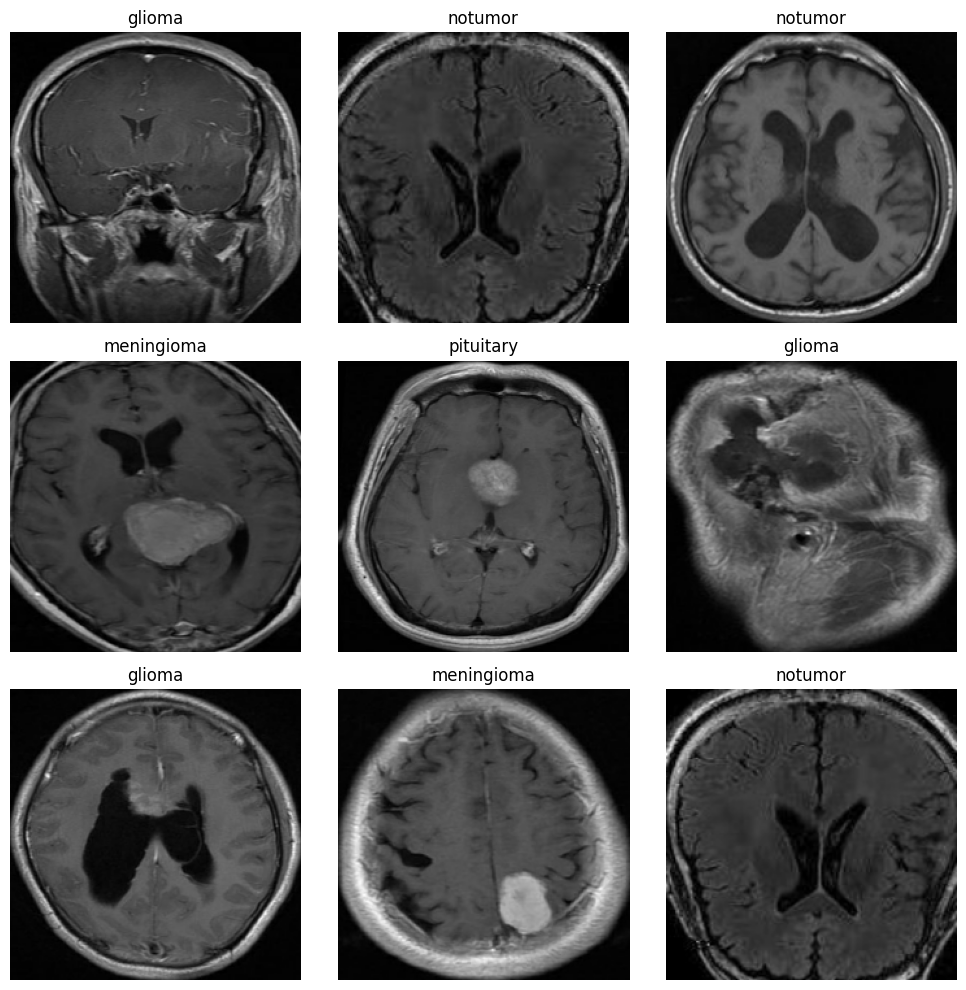

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 10))

for images, labels in train_ds.take(1):

    for i in range(9):

        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        class_index = tf.argmax(labels[i]).numpy()

        plt.title(train_ds.class_names[class_index])

        plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32, 4)


In [ ]:
print(train_ds.class_names)

['glioma', 'meningioma', 'notumor', 'pituitary']


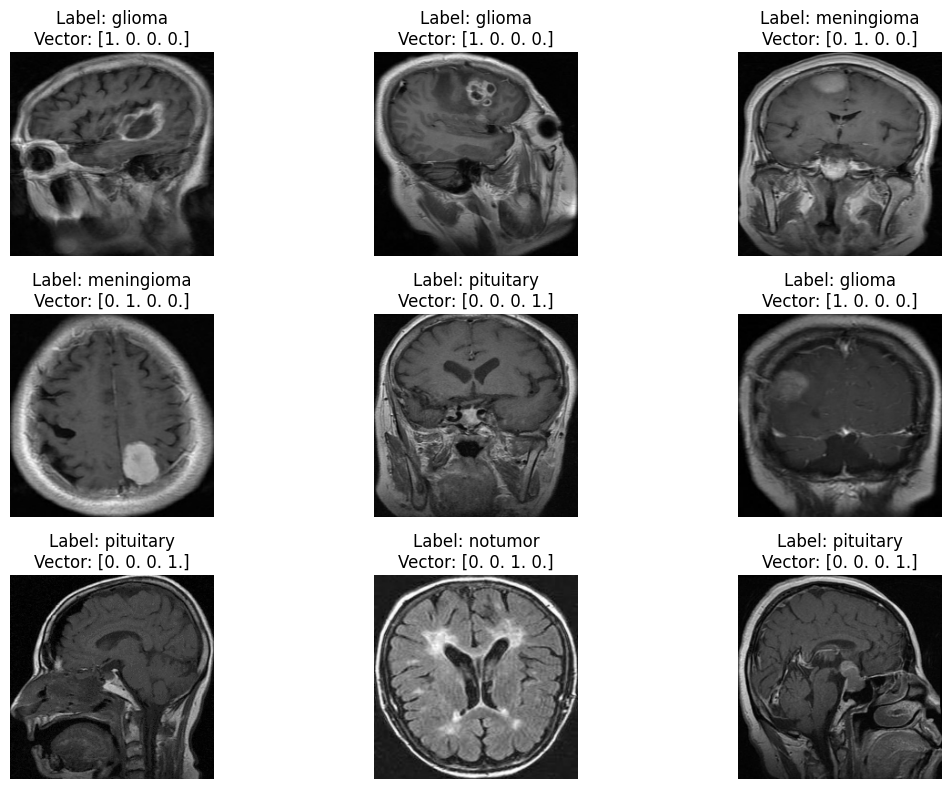

In [ ]:
import matplotlib.pyplot as plt
import tensorflow as tf

class_names = train_ds.class_names

for images, labels in train_ds.take(1):

    plt.figure(figsize=(12, 8))

    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)

        plt.imshow(images[i].numpy().astype("uint8"))

        label_index = tf.argmax(labels[i]).numpy()
        label_name = class_names[label_index]

        plt.title(
            f"Label: {label_name}\n"
            f"Vector: {labels[i].numpy()}"
        )

        plt.axis("off")

    plt.tight_layout()
    plt.show()

## Step 1 — Prepare datasets for EfficientNet-B0

In [ ]:
print("Training classes:", train_ds.class_names)
print("Number of classes:", len(train_ds.class_names))

Training classes: ['glioma', 'meningioma', 'notumor', 'pituitary']
Number of classes: 4


## Step 2 — Load the pretrained EfficientNet-B0 model

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, models

base_model = tf.keras.applications.EfficientNetB0(
    include_top=False,
    weights="imagenet",
    input_shape=(224, 224, 3)
)

print("EfficientNet-B0 loaded successfully.")

16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
EfficientNet-B0 loaded successfully.


In [ ]:
base_model.trainable = False

print("Base model trainable:", base_model.trainable)

Base model trainable: False


Build EfficientNet-B0 model

In [ ]:
inputs = tf.keras.Input(shape=(224, 224, 3))

# Apply the same augmentation used in preprocessing
x = data_augmentation(inputs)

# Pretrained EfficientNet-B0
x = base_model(x, training=False)

# Convert feature maps into a single feature vector
x = tf.keras.layers.GlobalAveragePooling2D()(x)

# Reduce overfitting
x = tf.keras.layers.Dropout(0.3)(x)

# Four MRI classes
outputs = tf.keras.layers.Dense(
    4,
    activation="softmax"
)(x)

efficientnet_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs
)

efficientnet_model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 4)              │         5,124 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,054,695 (15.47 MB)

 Trainable params: 5,124 (20.02 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [ ]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.001
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stopping_eff = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint_eff = tf.keras.callbacks.ModelCheckpoint(
    "best_efficientnet_b0.keras",
    monitor="val_loss",
    save_best_only=True
)

In [ ]:
history_eff = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        early_stopping_eff,
        checkpoint_eff
    ]
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 32s 133ms/step - accuracy: 0.6951 - loss: 0.7746 - val_accuracy: 0.7821 - val_loss: 0.5743
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 33s 102ms/step - accuracy: 0.8018 - loss: 0.5203 - val_accuracy: 0.7839 - val_loss: 0.5767
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 132ms/step - accuracy: 0.8386 - loss: 0.4519 - val_accuracy: 0.7866 - val_loss: 0.5488
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 105ms/step - accuracy: 0.8391 - loss: 0.4205 - val_accuracy: 0.8027 - val_loss: 0.5392
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 107ms/step - accuracy: 0.8542 - loss: 0.4035 - val_accuracy: 0.8045 - val_loss: 0.5171
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 106ms/step - accuracy: 0.8612 - loss: 0.3859 - val_accuracy: 0.8054 - val_loss: 0.5110
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 14s 102ms/step - accuracy: 0.8596 - loss: 0.3784 - val_accuracy: 0.7973 - val_loss: 0.5570
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 15s 108ms/step - accuracy: 0.8701 - loss: 0

Plot training and validation accuracy

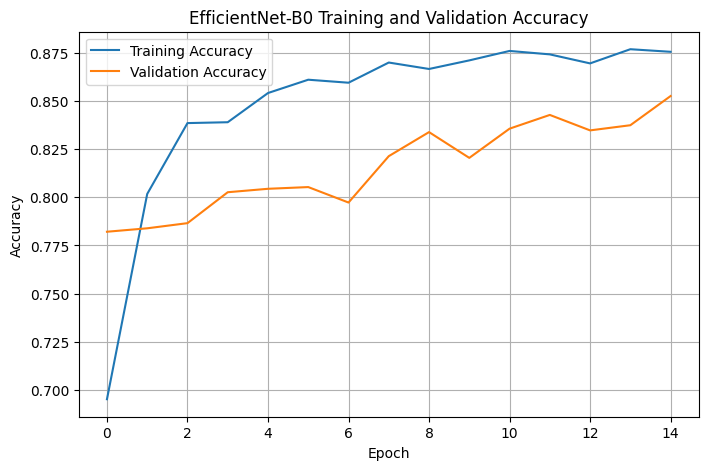

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(
    history_eff.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    history_eff.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNet-B0 Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.show()

Plot loss

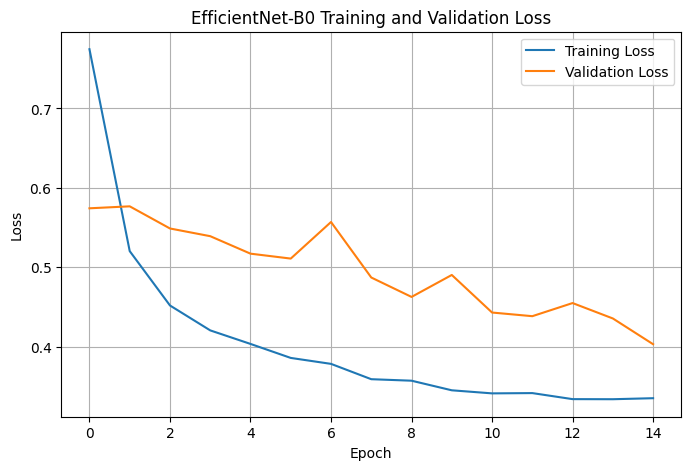

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_eff.history["loss"],
    label="Training Loss"
)

plt.plot(
    history_eff.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B0 Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

## Step 3 — Fine-tuning the pretrained EfficientNet-B0

In [ ]:
base_model.trainable = True

# Freeze most layers
for layer in base_model.layers[:-30]:
    layer.trainable = False

# Unfreeze the final 30 layers
for layer in base_model.layers[-30:]:
    layer.trainable = True

print("Total EfficientNet layers:", len(base_model.layers))

Total EfficientNet layers: 238


In [ ]:
for layer in base_model.layers:
    layer.trainable = False

for layer in base_model.layers[-30:]:
    if not isinstance(
        layer,
        tf.keras.layers.BatchNormalization
    ):
        layer.trainable = True

Check trainable layers

In [ ]:
trainable_layers = [
    layer.name
    for layer in base_model.layers
    if layer.trainable
]

print("Number of trainable layers:", len(trainable_layers))

print("\nTrainable layers:")
for layer in trainable_layers:
    print(layer)

Number of trainable layers: 23

Trainable layers:
block6d_expand_activation
block6d_dwconv
block6d_activation
block6d_se_squeeze
block6d_se_reshape
block6d_se_reduce
block6d_se_expand
block6d_se_excite
block6d_project_conv
block6d_drop
block6d_add
block7a_expand_conv
block7a_expand_activation
block7a_dwconv
block7a_activation
block7a_se_squeeze
block7a_se_reshape
block7a_se_reduce
block7a_se_expand
block7a_se_excite
block7a_project_conv
top_conv
top_activation


In [ ]:
efficientnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-5
    ),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
early_stopping_fine = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

checkpoint_fine = tf.keras.callbacks.ModelCheckpoint(
    "best_efficientnet_b0_finetuned.keras",
    monitor="val_loss",
    save_best_only=True
)

In [ ]:
fine_tune_history = efficientnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=15,
    callbacks=[
        early_stopping_fine,
        checkpoint_fine
    ]
)

Epoch 1/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 31s 137ms/step - accuracy: 0.8837 - loss: 0.3140 - val_accuracy: 0.8554 - val_loss: 0.4037
Epoch 2/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 18s 128ms/step - accuracy: 0.8835 - loss: 0.3017 - val_accuracy: 0.8571 - val_loss: 0.4059
Epoch 3/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 115ms/step - accuracy: 0.8906 - loss: 0.2941 - val_accuracy: 0.8580 - val_loss: 0.3871
Epoch 4/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 114ms/step - accuracy: 0.8973 - loss: 0.2849 - val_accuracy: 0.8607 - val_loss: 0.3833
Epoch 5/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 16s 116ms/step - accuracy: 0.8942 - loss: 0.2770 - val_accuracy: 0.8589 - val_loss: 0.3832
Epoch 6/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 21s 117ms/step - accuracy: 0.9002 - loss: 0.2708 - val_accuracy: 0.8634 - val_loss: 0.3763
Epoch 7/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 20s 110ms/step - accuracy: 0.9029 - loss: 0.2634 - val_accuracy: 0.8598 - val_loss: 0.3940
Epoch 8/15
140/140 ━━━━━━━━━━━━━━━━━━━━ 19s 133ms/step - accuracy: 0.9049 - loss: 0

Plot fine-tuning results

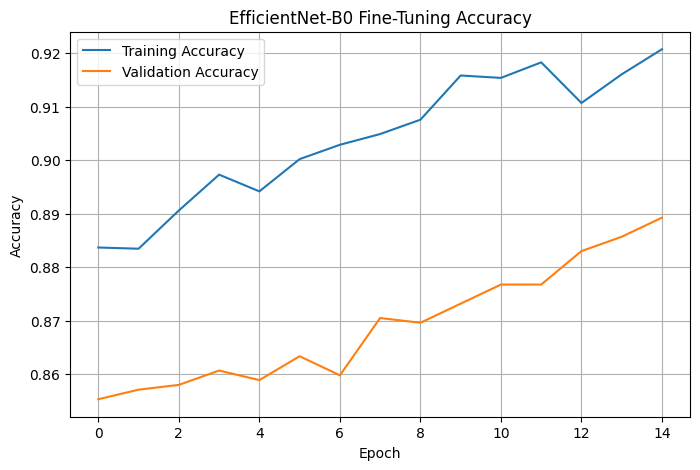

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    fine_tune_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    fine_tune_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNet-B0 Fine-Tuning Accuracy")
plt.legend()
plt.grid(True)

plt.show()

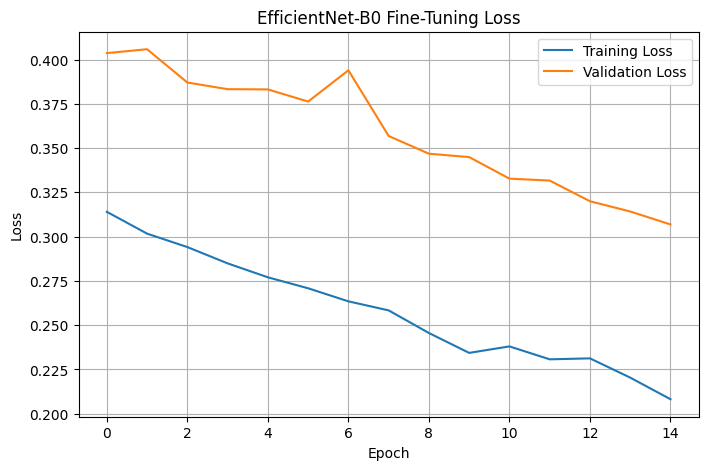

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(
    fine_tune_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    fine_tune_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNet-B0 Fine-Tuning Loss")
plt.legend()
plt.grid(True)

plt.show()

In [ ]:
test_loss, test_accuracy = efficientnet_model.evaluate(
    test_ds
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

50/50 ━━━━━━━━━━━━━━━━━━━━ 4s 76ms/step - accuracy: 0.8494 - loss: 0.4023
Test Loss: 0.40233489871025085
Test Accuracy: 0.8493750095367432


Get predictions

In [ ]:
import numpy as np

y_true = []
y_pred = []
y_prob = []

for images, labels in test_ds:

    predictions = efficientnet_model.predict(
        images,
        verbose=0
    )

    predicted_classes = np.argmax(
        predictions,
        axis=1
    )

    true_classes = np.argmax(
        labels.numpy(),
        axis=1
    )

    y_true.extend(true_classes)
    y_pred.extend(predicted_classes)
    y_prob.extend(predictions)

y_true = np.array(y_true)
y_pred = np.array(y_pred)
y_prob = np.array(y_prob)

print("Predictions completed.")

Predictions completed.


Classification report

In [ ]:
from sklearn.metrics import classification_report

print(
    classification_report(
        y_true,
        y_pred,
        target_names=train_ds.class_names
    )
)

              precision    recall  f1-score   support

      glioma       0.94      0.66      0.78       400
  meningioma       0.77      0.75      0.76       400
     notumor       0.95      0.99      0.97       400
   pituitary       0.78      1.00      0.88       400

    accuracy                           0.85      1600
   macro avg       0.86      0.85      0.84      1600
weighted avg       0.86      0.85      0.84      1600



Calculate Accuracy, Precision, Recall and F1

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_true, y_pred)

precision = precision_score(
    y_true,
    y_pred,
    average="weighted"
)

recall = recall_score(
    y_true,
    y_pred,
    average="weighted"
)

f1 = f1_score(
    y_true,
    y_pred,
    average="weighted"
)

print("EfficientNet-B0 Results")
print("------------------------")
print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

EfficientNet-B0 Results
------------------------
Accuracy : 0.849375
Precision: 0.8594407967641844
Recall   : 0.849375
F1 Score : 0.8449392563736954


ROC-AUC

In [ ]:
from sklearn.metrics import roc_auc_score

roc_auc = roc_auc_score(
    y_true,
    y_prob,
    multi_class="ovr",
    average="weighted"
)

print("ROC-AUC:", roc_auc)

ROC-AUC: 0.977228125


Confusion Matrix

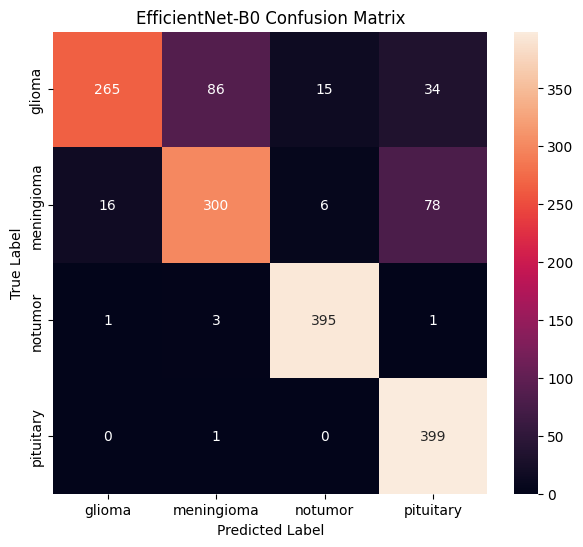

In [ ]:
from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

cm = confusion_matrix(
    y_true,
    y_pred
)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=train_ds.class_names,
    yticklabels=train_ds.class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("EfficientNet-B0 Confusion Matrix")

plt.show()

Count model parameters

In [ ]:
print(
    "Total parameters:",
    efficientnet_model.count_params()
)

Total parameters: 4054695
